# 04 — Regularised linear models: ridge, lasso, elastic net

Phase 4 showed that plain OLS works well (grouped-CV R² 0.845), but some coefficients are unstable. RAM vs storage and screen vs weight swap importance depending on what else is in the model. **Regularisation** adds a penalty on the size of the coefficients to the least-squares objective, trading a little bias for a lot less variance:

- **Ridge:** minimise ‖y − Xw‖² + α‖w‖² (sum of *squared* coefficients). It shrinks all coefficients smoothly towards 0.
- **Lasso:** minimise (1/2n)‖y − Xw‖² + α‖w‖₁ (sum of *absolute* coefficients). It can set coefficients **exactly** to 0, so it also selects features.
- **Elastic net:** a mix of the two penalties.

α (written λ in lectures) controls the penalty strength: α → 0 gives OLS, and a very large α shrinks everything to 0. We choose α by **grouped 5-fold cross-validation on the training set**, as in Phase 4.

**Pipeline.** All preprocessing sits inside a scikit-learn **Pipeline**, so in every CV fold it is fitted on that fold's training part only:
- `StandardScaler` on the numeric features, so that the penalty treats all features fairly. Otherwise a feature measured in mAh (thousands) would get a tiny coefficient, and hence a tiny penalty, just because of its units.
- `OneHotEncoder(handle_unknown="ignore")` on brand and chip group. Here we keep **all** dummies (no reference category). With OLS that would make XᵀX singular, but the penalty makes the solution unique, as section 1 shows.

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

from features import NUMERIC_FEATURES, CATEGORICAL_FEATURES
from split import load_train_test, cv_folds
from evaluate import grouped_cv_scores, summarise, pretty

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0",
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message="Objective did not converge")

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
train, _ = load_train_test(include_web_lookup=True)
train_name, _ = load_train_test(include_web_lookup=False)
print("training phones:", len(train), "| name-only:", len(train_name))

def make_pipeline(model):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])
    return Pipeline([("pre", pre), ("model", model)])

def tune(model, grid, data):
    # Grid search with the saved grouped 5-fold CV on the given training data.
    # Score = negative mean squared error on log price (higher is better).
    search = GridSearchCV(make_pipeline(model), grid, cv=cv_folds(data), scoring="neg_mean_squared_error")
    search.fit(data[FEATURES], data["log_price"])
    return search

def pipeline_fit_predict(model):
    def fit_predict(fit_rows, pred_rows):
        pipe = make_pipeline(model).fit(fit_rows[FEATURES], fit_rows["log_price"])
        return pipe.predict(pred_rows[FEATURES])
    return fit_predict

def coef_series(pipe):
    names = pipe.named_steps["pre"].get_feature_names_out()
    names = [n.replace("num__", "").replace("cat__", "") for n in names]
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

training phones: 558 | name-only: 555


## 1. Ridge regression
### 1a. Choosing α by grouped cross-validation
We try 50 values of α spaced evenly on a log scale from 0.001 to 1000 (`np.logspace(-3, 3, 50)`) and pick the one with the lowest mean validation error. The error is the **mean squared error (MSE)** on log price.

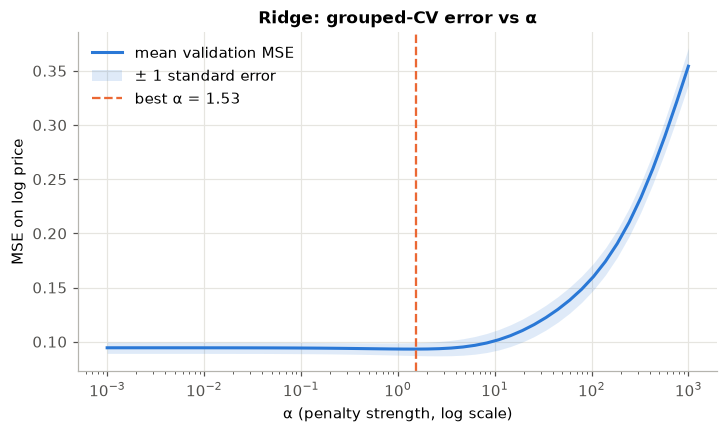

best α = 1.526, CV MSE = 0.0932; MSE at smallest α (≈ OLS) = 0.0944; at largest α = 0.3543


In [2]:
ridge_alphas = np.logspace(-3, 3, 50)
ridge_search = tune(Ridge(), {"model__alpha": ridge_alphas}, train)
cv = pd.DataFrame(ridge_search.cv_results_)
mse_mean, mse_std = -cv["mean_test_score"].to_numpy(), cv["std_test_score"].to_numpy()
best_ridge_alpha = ridge_search.best_params_["model__alpha"]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(ridge_alphas, mse_mean, color=BLUE, linewidth=2, label="mean validation MSE")
ax.fill_between(ridge_alphas, mse_mean - mse_std / np.sqrt(5), mse_mean + mse_std / np.sqrt(5),
                color=BLUE, alpha=0.15, linewidth=0, label="± 1 standard error")
ax.axvline(best_ridge_alpha, color=ORANGE, linewidth=1.5, linestyle="--", label=f"best α = {best_ridge_alpha:.3g}")
ax.set_xscale("log")
ax.set(title="Ridge: grouped-CV error vs α", xlabel="α (penalty strength, log scale)", ylabel="MSE on log price")
ax.legend(frameon=False)
fig.savefig("../results/fig04_ridge_cv.png")
plt.show()
print(f"best α = {best_ridge_alpha:.4g}, CV MSE = {mse_mean.min():.4f}; "
      f"MSE at smallest α (≈ OLS) = {mse_mean[0]:.4f}; at largest α = {mse_mean[-1]:.4f}")

**Takeaway:** the error curve is flat from α = 0.001 up to about α = 3, then rises steeply as heavy shrinkage starts to remove real signal. The best α is **1.53**, with CV MSE 0.0932 against 0.0944 at α ≈ 0 (i.e. OLS), about a **1 % improvement**. This fits Phase 4: collinearity among our features is only moderate (condition number 17 for the numeric features), so OLS was not badly overfitting, and ridge has little variance to remove.

### 1b. Coefficient paths
A **coefficient path** shows how each coefficient changes as α grows. Numeric coefficients are in standardised units: the change in log price for a one-standard-deviation increase in the feature.

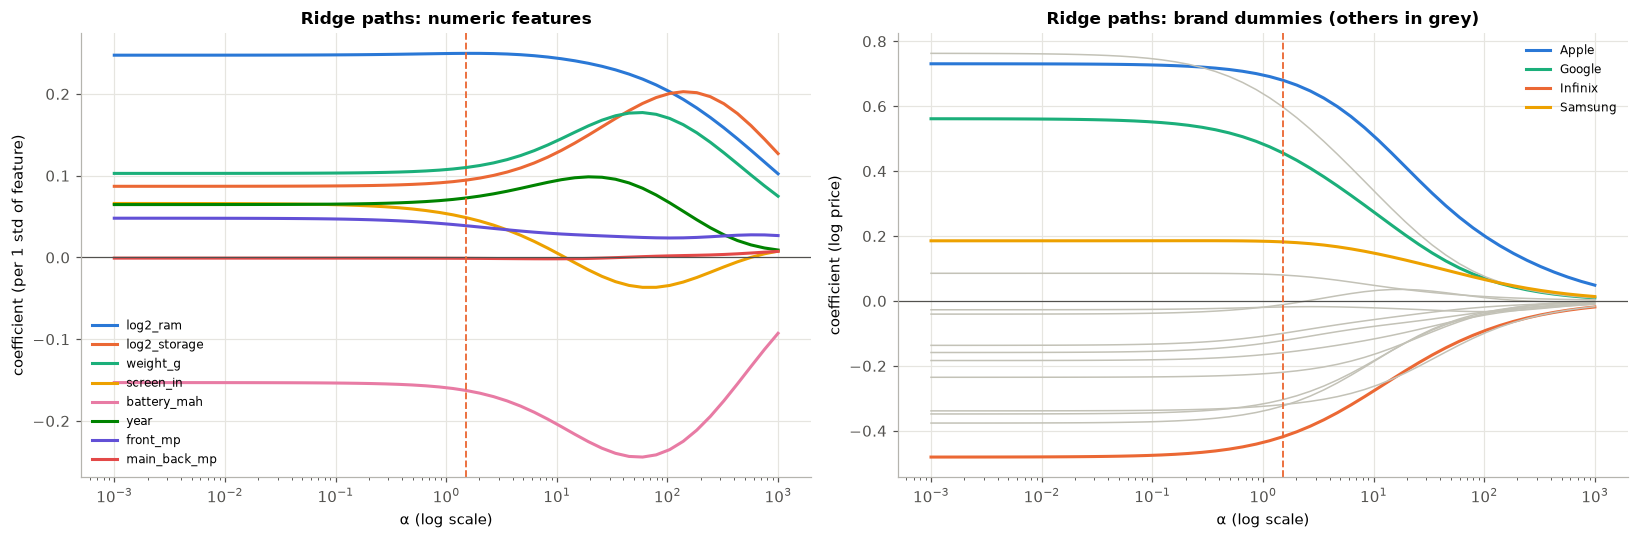

In [3]:
path = pd.DataFrame({a: coef_series(make_pipeline(Ridge(alpha=a)).fit(train[FEATURES], train["log_price"])) for a in ridge_alphas}).T

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for i, col in enumerate(["log2_ram", "log2_storage", "weight_g", "screen_in", "battery_mah", "year", "front_mp", "main_back_mp"]):
    axes[0].plot(ridge_alphas, path[col], color=SERIES[i], linewidth=2, label=col)
axes[0].set(title="Ridge paths: numeric features", xlabel="α (log scale)", ylabel="coefficient (per 1 std of feature)")
brand_cols = [c for c in path.columns if c.startswith("brand_")]
for c in brand_cols:
    highlight = {"brand_Apple": SERIES[0], "brand_Infinix": SERIES[1], "brand_Google": SERIES[2], "brand_Samsung": SERIES[3]}
    axes[1].plot(ridge_alphas, path[c], color=highlight.get(c, "#c3c2b7"), linewidth=2 if c in highlight else 1,
                 label=c.replace("brand_", "") if c in highlight else None)
axes[1].set(title="Ridge paths: brand dummies (others in grey)", xlabel="α (log scale)", ylabel="coefficient (log price)")
for ax in axes:
    ax.set_xscale("log"); ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.axvline(best_ridge_alpha, color=ORANGE, linewidth=1.2, linestyle="--")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("../results/fig04_ridge_paths.png")
plt.show()

**Takeaway:** at the chosen α (dashed line) every coefficient is still almost at its OLS value; the visible shrinkage only begins around α ≈ 3–10. Two patterns are worth noting as α grows:
- **RAM and storage converge.** The RAM coefficient falls while storage *rises*, until near α ≈ 100 they are about equal. This is ridge's typical behaviour with correlated features: when the data cannot tell them apart, the penalty prefers to **share** the effect between them (two medium coefficients have a smaller sum of squares than one big and one small). Weight and year rise for a while for the same reason.
- **Brand coefficients shrink towards each other.** Apple and Google (high premiums) and Infinix (low) all move towards 0, i.e. towards "brand does not matter", only at very large α.

### 1c. Why ridge stabilises: the eigenvalue view
Write the (centred) design matrix as X and let XᵀX have eigenvalues λ₁ ≥ … ≥ λ_p with eigenvectors v₁ … v_p (the "directions" in feature space). In that basis the ridge solution is the OLS solution with the component along each direction vᵢ multiplied by

**shrink factor = λᵢ / (λᵢ + α)**.

- A direction with a **large** λᵢ is well supported by the data (features vary a lot along it). Its factor is close to 1, so it is hardly shrunk.
- A direction with a **small** λᵢ is poorly supported. OLS estimates it with huge variance (∝ 1/λᵢ), and ridge shrinks it strongly.
- A direction with λᵢ = 0 (an exact redundancy) gets factor 0, so ridge simply ignores it. That is why keeping **all** brand and chip dummies is fine: the dummies of one category always sum to 1, which after centring is an exact zero-eigenvalue direction.

We compute the eigenvalues of the centred, preprocessed training matrix (sklearn's `Ridge` centres X internally to fit the intercept) and the shrink factor at the chosen α.

33 directions; 2 have eigenvalue ~0 (one per one-hot category set)

Smallest 8 eigenvalues:
   eigenvalue λ  shrink factor at α=1.53                                                                                top features in this direction
0        -0.000                   -0.000  chip_group_dimensity_high(-0.33), chip_group_flagship_sd8_or_apple(-0.33), chip_group_dimensity_other(-0.33)
1         0.000                    0.000                                                  brand_Other(+0.25), brand_Google(+0.25), brand_Lenovo(+0.25)
2         1.952                    0.561                                         chip_group_kirin(+0.80), brand_Other(-0.49), chip_group_tensor(-0.17)
3         2.591                    0.629                                       chip_group_tensor(+0.71), brand_Google(-0.61), chip_group_unisoc(-0.15)
4         5.170                    0.772                                             brand_Nokia(-0.74), brand_Xiaomi(+0.33), chip_group_unisoc(+0.28)
5 

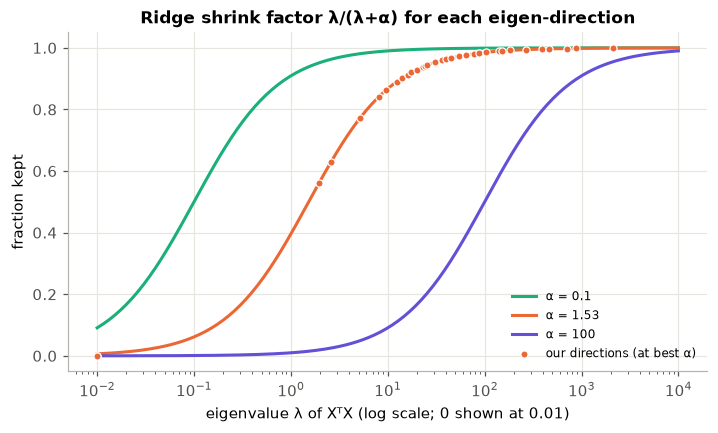

In [4]:
pre = make_pipeline(Ridge()).named_steps["pre"].fit(train[FEATURES])
Xp = pre.transform(train[FEATURES])
Xp = np.asarray(Xp.todense()) if hasattr(Xp, "todense") else Xp
names = [n.replace("num__", "").replace("cat__", "") for n in pre.get_feature_names_out()]
Xc = Xp - Xp.mean(axis=0)
eigvals, eigvecs = np.linalg.eigh(Xc.T @ Xc)
eig = pd.DataFrame({"eigenvalue λ": eigvals, f"shrink factor at α={best_ridge_alpha:.3g}": eigvals / (eigvals + best_ridge_alpha)})
eig["top features in this direction"] = [", ".join(f"{names[j]}({eigvecs[j, i]:+.2f})" for j in np.argsort(-np.abs(eigvecs[:, i]))[:3])
                                         for i in range(len(eigvals))]
print(f"{len(eigvals)} directions; {np.sum(eigvals < 1e-8)} have eigenvalue ~0 (one per one-hot category set)")
with pd.option_context("display.max_colwidth", 80):
    print("\nSmallest 8 eigenvalues:"); print(eig.head(8).round(3).to_string())
    print("\nLargest 3 eigenvalues:"); print(eig.tail(3).round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
lam = np.logspace(-2, 4, 200)
for a, c in [(0.1, SERIES[2]), (best_ridge_alpha, ORANGE), (100, SERIES[6])]:
    ax.plot(lam, lam / (lam + a), color=c, linewidth=2, label=f"α = {a:.3g}")
ax.scatter(np.clip(eigvals, 1e-2, None), eigvals / (eigvals + best_ridge_alpha), color=ORANGE, s=22, zorder=3,
           edgecolor="white", linewidth=0.8, label="our directions (at best α)")
ax.set_xscale("log")
ax.set(title="Ridge shrink factor λ/(λ+α) for each eigen-direction", xlabel="eigenvalue λ of XᵀX (log scale; 0 shown at 0.01)", ylabel="fraction kept")
ax.legend(frameon=False, fontsize=8)
fig.savefig("../results/fig04_shrink_factors.png")
plt.show()

**Takeaway:** the 33 preprocessed columns have 33 eigen-directions.
- **Two eigenvalues are exactly 0**, one for the brand dummies and one for the chip dummies (each set sums to 1). OLS has no unique solution along these directions. Ridge's factor 0/(0+α) = 0 simply sets those components to zero, which is why keeping all dummies is harmless here.
- The **smallest non-zero eigenvalues** are 1.95 and 2.59, and their eigenvectors are "Kirin chip vs brand Other" and "Tensor chip vs brand Google". These are the same brand-specific chips that confused Model A: the data barely separates "Huawei's chip" from "Huawei's brand", or "Google's chip" from "Google's brand". At the chosen α ridge keeps only **56 % and 63 %** of these components, so this is where it acts most.
- The largest eigenvalues (700–2100) are broad mixes of the numeric specs (e.g. "more RAM + bigger screen + more storage"). Their factor is 0.998–0.999, i.e. untouched.

So, as in lectures: ridge leaves the well-determined directions alone and shrinks exactly the unstable ones. Here those are the brand-vs-own-chip directions rather than RAM vs storage, whose direction (eigenvalue ≈ 120 in Phase 4's scaling) is still well supported.

## 2. RAM and storage: OLS vs ridge
We now compare the two coefficients that Phase 4 found unstable. To put both models on the same footing we fit them on **exactly the same pipeline** (all dummies, standardised numerics). For OLS that requires a tiny α (1e-6), because the full set of dummies is singular without a penalty. We then convert each coefficient to "% price change for doubling", dividing the standardised coefficient by the standard deviation of log2 RAM / log2 storage.

In [5]:
def doubling_effects(alpha, data):
    pipe = make_pipeline(Ridge(alpha=alpha)).fit(data[FEATURES], data["log_price"])
    coef, sd = coef_series(pipe), pipe.named_steps["pre"].named_transformers_["num"].scale_
    sd = pd.Series(sd, index=NUMERIC_FEATURES)
    b_ram, b_sto = coef["log2_ram"] / sd["log2_ram"], coef["log2_storage"] / sd["log2_storage"]
    return {"RAM ×2 (%)": 100 * (np.exp(b_ram) - 1), "storage ×2 (%)": 100 * (np.exp(b_sto) - 1),
            "both ×2 (%)": 100 * (np.exp(b_ram + b_sto) - 1),
            "RAM coef (std units)": coef["log2_ram"], "storage coef (std units)": coef["log2_storage"]}

ram_sto = pd.DataFrame({f"OLS (α≈0)": doubling_effects(1e-6, train),
                        f"Ridge (α={best_ridge_alpha:.3g})": doubling_effects(best_ridge_alpha, train),
                        "Ridge (α=100, heavy)": doubling_effects(100, train)}).T.round(3)
ram_sto

,RAM ×2 (%),storage ×2 (%),both ×2 (%),RAM coef (std units),storage coef (std units)
OLS (α≈0),48.409,10.043,63.315,0.247,0.087
Ridge (α=1.53),48.941,10.967,65.276,0.250,0.095
"Ridge (α=100, heavy)",38.528,24.588,72.589,0.204,0.200


**Takeaway:** at the CV-chosen α, ridge gives practically the **same** answer as OLS: doubling RAM +48.9 % vs +48.4 %, doubling storage +11.0 % vs +10.0 %. The RAM–storage direction is not weak enough for α = 1.53 to move it. Only with heavy shrinkage (α = 100) does ridge pull them together (RAM +38.5 %, storage +24.6 %). The *combined* effect of doubling both stays far more stable (+63 % OLS, +65 % ridge) than either part.

So the honest statement for the report is: *the data clearly says that more memory (RAM and storage together) is worth about +60 % per doubling, but how that splits between RAM and storage is only weakly determined and depends on the model.*

## 3. Lasso
The lasso uses the absolute-value penalty α‖w‖₁. Its corners make it set some coefficients **exactly to zero**, so it performs feature selection. sklearn's lasso divides the squared error by 2n, so its α is on a different scale from ridge's. We search `np.logspace(-4, 0, 50)` instead (0.0001 to 1), which covers the range from "almost OLS" to "everything zero".

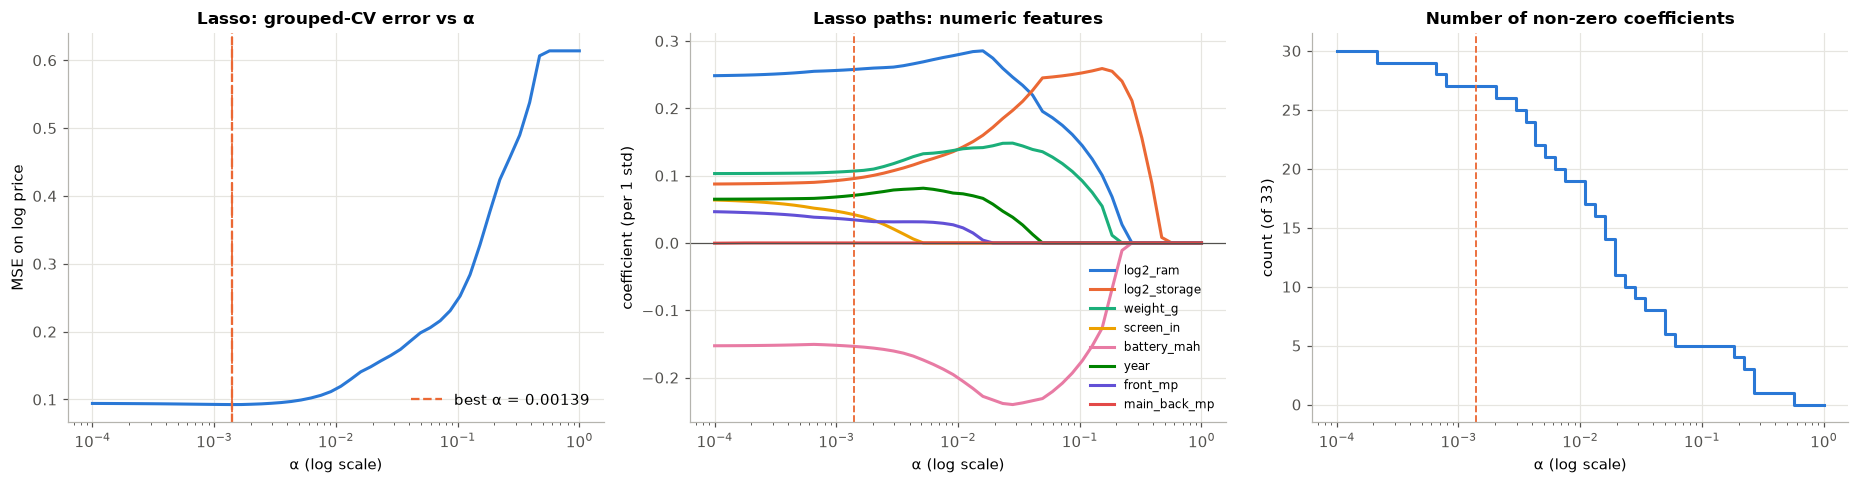

α at which each numeric feature is dropped for good (smaller = dropped earlier = less useful):
main_back_mp      0.0002
n_back_cameras    0.0036
screen_in         0.0052
front_mp          0.0193
year              0.0494
weight_g          0.2223
battery_mah       0.2683
log2_ram          0.2683
log2_storage      0.5690


In [6]:
lasso_alphas = np.logspace(-4, 0, 50)
lasso_search = tune(Lasso(max_iter=50000), {"model__alpha": lasso_alphas}, train)
lcv = pd.DataFrame(lasso_search.cv_results_)
best_lasso_alpha = lasso_search.best_params_["model__alpha"]

lasso_path = pd.DataFrame({a: coef_series(make_pipeline(Lasso(alpha=a, max_iter=50000)).fit(train[FEATURES], train["log_price"]))
                           for a in lasso_alphas}).T
n_nonzero = (lasso_path.abs() > 1e-10).sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(lasso_alphas, -lcv["mean_test_score"], color=BLUE, linewidth=2)
axes[0].axvline(best_lasso_alpha, color=ORANGE, linestyle="--", label=f"best α = {best_lasso_alpha:.3g}")
axes[0].set(title="Lasso: grouped-CV error vs α", xlabel="α (log scale)", ylabel="MSE on log price")
for i, col in enumerate(["log2_ram", "log2_storage", "weight_g", "screen_in", "battery_mah", "year", "front_mp", "main_back_mp"]):
    axes[1].plot(lasso_alphas, lasso_path[col], color=SERIES[i], linewidth=2, label=col)
axes[1].set(title="Lasso paths: numeric features", xlabel="α (log scale)", ylabel="coefficient (per 1 std)")
axes[2].plot(lasso_alphas, n_nonzero, color=BLUE, linewidth=2, drawstyle="steps-post")
axes[2].set(title="Number of non-zero coefficients", xlabel="α (log scale)", ylabel=f"count (of {lasso_path.shape[1]})")
for ax in axes:
    ax.set_xscale("log"); ax.axvline(best_lasso_alpha, color=ORANGE, linestyle="--", linewidth=1.2)
axes[0].legend(frameon=False); axes[1].legend(frameon=False, fontsize=8); axes[1].axhline(0, color=MUTED, linewidth=0.8)
fig.tight_layout()
fig.savefig("../results/fig04_lasso.png")
plt.show()

# The alpha at which each numeric feature first becomes (and stays) zero
drop_alpha = {}
for col in lasso_path.columns:
    nz = lasso_path[col].abs() > 1e-10
    drop_alpha[col] = lasso_alphas[nz.to_numpy().nonzero()[0].max() + 1] if nz.any() and nz.to_numpy().nonzero()[0].max() + 1 < len(lasso_alphas) else (np.nan if nz.any() else lasso_alphas[0])
order = pd.Series(drop_alpha)[NUMERIC_FEATURES].sort_values()
print("α at which each numeric feature is dropped for good (smaller = dropped earlier = less useful):")
print(order.map(lambda a: f"{a:.4f}" if pd.notna(a) else "never in range").to_string())

In [7]:
best_lasso = lasso_search.best_estimator_
lasso_coef = coef_series(best_lasso)
print(f"At the chosen α = {best_lasso_alpha:.4g}: {int((lasso_coef.abs() > 1e-10).sum())} of {len(lasso_coef)} coefficients are non-zero.\n")
print("Set exactly to ZERO:", ", ".join(lasso_coef[lasso_coef.abs() <= 1e-10].index))
print("\nSurviving coefficients (sorted by size):")
print(lasso_coef[lasso_coef.abs() > 1e-10].sort_values(key=abs, ascending=False).round(4).to_string())
lasso_coef.to_csv("../results/lasso_coefficients.csv", header=["coef"])

At the chosen α = 0.001389: 27 of 33 coefficients are non-zero.

Set exactly to ZERO: main_back_mp, brand_Nokia, brand_Tecno, chip_group_kirin, chip_group_snapdragon_other, chip_group_tensor

Surviving coefficients (sorted by size):
brand_Apple                         0.7870
brand_Other                         0.6898
brand_Google                        0.6089
chip_group_flagship_sd8_or_apple    0.4559
chip_group_unisoc                  -0.3893
brand_Infinix                      -0.3085
brand_Samsung                       0.2833
chip_group_helio                   -0.2750
log2_ram                            0.2577
brand_Realme                       -0.2465
chip_group_dimensity_high           0.2055
brand_Lenovo                       -0.1916
brand_POCO                         -0.1840
battery_mah                        -0.1537
brand_OnePlus                      -0.1225
chip_group_dimensity_other         -0.1137
weight_g                            0.1067
log2_storage                        

**Takeaway:**
- The CV-best lasso uses a **small** α = 0.0014 and keeps **27 of 33** coefficients. Like ridge, the data prefers little regularisation.
- At that α the lasso sets to exactly zero: **main camera MP** (no information once other specs are known, as in Phase 4), the **Nokia** and **Tecno** brand dummies, and the **Kirin, Tensor and Snapdragon-other** chip dummies. Dropping one dummy per set is just the lasso choosing its own reference categories. Dropping Kirin and Tensor matches the ridge eigen-analysis: those chips are not separable from their brands (Huawei/"Other", Google), so the lasso lets the brand carry the effect.
- **Order in which numeric features drop out** as α grows (earliest = least useful): main camera MP → number of back cameras → screen → front camera → year → weight → RAM and battery → **storage last**. When the penalty forces a choice between the correlated pair RAM/storage, the lasso keeps storage and drops RAM (middle panel). That is the lasso's typical behaviour with correlated features: it keeps one and discards the other, whereas ridge shares the effect between them.

## 4. Elastic net (optional)
The penalty is α · [l1_ratio · ‖w‖₁ + (1 − l1_ratio)/2 · ‖w‖²]: l1_ratio = 1 is the lasso and l1_ratio → 0 approaches ridge. We search l1_ratio ∈ {0.2, 0.5, 0.8} together with α.

In [8]:
enet_search = tune(ElasticNet(max_iter=50000), {"model__alpha": np.logspace(-4, 0, 30), "model__l1_ratio": [0.2, 0.5, 0.8]}, train)
best_enet = enet_search.best_params_
enet_coef = coef_series(enet_search.best_estimator_)
print(f"best: alpha = {best_enet['model__alpha']:.4g}, l1_ratio = {best_enet['model__l1_ratio']}, CV MSE = {-enet_search.best_score_:.4f}; "
      f"zero coefficients: {int((enet_coef.abs() <= 1e-10).sum())} of {len(enet_coef)}")

best: alpha = 0.001743, l1_ratio = 0.8, CV MSE = 0.0925; zero coefficients: 5 of 33


**Takeaway:** the elastic net picks l1_ratio = 0.8 and a small α (0.0017) and zeros 5 coefficients. Its CV error (MSE 0.0925) equals the lasso's and is marginally below ridge's (0.0932), a difference far smaller than the fold-to-fold noise.

## 5. Comparison table (grouped CV on the training set)
The Phase 4 rows are read from `results/cv_phase4.csv`. The new rows use the chosen α refitted inside each fold, with the same folds.

One caution: α was chosen with these same folds, so the regularised models' CV scores are very slightly optimistic. With a single tuning parameter the effect is small, and the untouched test set in Phase 7 gives the unbiased check.

In [9]:
best = {
    "Ridge": Ridge(alpha=best_ridge_alpha),
    "Lasso": Lasso(alpha=best_lasso_alpha, max_iter=50000),
    "Elastic net": ElasticNet(alpha=best_enet["model__alpha"], l1_ratio=best_enet["model__l1_ratio"], max_iter=50000),
}
phase4 = pd.read_csv("../results/cv_phase4.csv")
rows = phase4.to_dict("records")
for name, model in best.items():
    rows.append(summarise(grouped_cv_scores(pipeline_fit_predict(model), train), name))
pd.DataFrame(rows).to_csv("../results/cv_phase5.csv", index=False)
pretty(rows)

,R² (log price),median % error,MAE (₹)
model,,,
Baseline 1: overall mean,-0.006 ± 0.005,59.1 ± 2.4,"29,797 ± 2,812"
Baseline 2: brand mean,0.366 ± 0.056,40.3 ± 3.1,"22,181 ± 2,706"
Model A: specs + chip,0.773 ± 0.039,23.3 ± 1.7,"14,273 ± 2,048"
Model B: specs + chip + brand,0.845 ± 0.018,18.2 ± 2.2,"11,757 ± 1,658"
Ridge,0.847 ± 0.019,18.3 ± 2.4,"11,588 ± 1,767"
Lasso,0.848 ± 0.019,18.0 ± 2.1,"11,633 ± 1,807"
Elastic net,0.848 ± 0.019,18.1 ± 2.0,"11,617 ± 1,813"


**Takeaway:** ridge, lasso and elastic net all reach **R² ≈ 0.848** (0.847–0.848) and a median error of **18.0–18.3 %**, practically the same as OLS Model B (0.845, 18.2 %) and well inside the fold-to-fold standard deviation (± 0.02). **Regularisation does not improve accuracy here** — with 558 phones and 33 columns, and only moderate collinearity, OLS was not overfitting much. Its value in this project is **stability and interpretability**: unique coefficients with all brands kept (needed for the brand-premium analysis in Phase 8) and a principled answer to the redundant-dummy problem. We carry **ridge** forward as the main linear model.

## 6. Robustness: name-only training data
We repeat the α search and the CV scores without the 3 web-lookup phones in the training set.

In [10]:
rob = []
for name, (model_cls, grid, kw) in {"Ridge": (Ridge, {"model__alpha": ridge_alphas}, {}),
                                     "Lasso": (Lasso, {"model__alpha": lasso_alphas}, {"max_iter": 50000})}.items():
    for label, data in [("with web lookup", train), ("name-only", train_name)]:
        s = tune(model_cls(**kw), grid, data)
        a = s.best_params_["model__alpha"]
        sc = summarise(grouped_cv_scores(pipeline_fit_predict(model_cls(alpha=a, **kw)), data), name)
        eff = doubling_effects(a, data) if name == "Ridge" else {}
        rob.append({"model": name, "data": label, "best α": round(a, 4), "CV R²": round(sc["R2_log_mean"], 3),
                    "median % error": round(sc["median_pct_error_mean"], 1),
                    "RAM ×2 %": round(eff.get("RAM ×2 (%)", np.nan), 1), "storage ×2 %": round(eff.get("storage ×2 (%)", np.nan), 1)})
rob = pd.DataFrame(rob)
rob.to_csv("../results/cv_phase5_robustness.csv", index=False)
rob

,model,data,best α,CV R²,median % error,RAM ×2 %,storage ×2 %
0,Ridge,with web lookup,1.5264,0.847,18.3,48.9,11.0
1,Ridge,name-only,1.5264,0.848,18.0,49.9,10.3
2,Lasso,with web lookup,0.0014,0.848,18.0,NaN,NaN
3,Lasso,name-only,0.0014,0.849,18.0,NaN,NaN


**Takeaway:** without the web-lookup phones, ridge picks the same α (1.53) and nearly the same CV R² (0.848 vs 0.847). The lasso picks the same α (0.0014) with R² 0.849 vs 0.848. The RAM and storage effects move by about 1 percentage point. The conclusions do not depend on the 7 phones.

## Summary
- Cross-validation chooses **light regularisation** for all three methods (ridge α = 1.53; lasso α = 0.0014; elastic net α = 0.0017 with l1_ratio 0.8). All three reach grouped-CV **R² 0.847–0.848**, essentially equal to OLS (0.845). Regularisation buys stability, not accuracy, on this dataset.
- The **eigenvalue view** shows where ridge acts. Exact redundancies (all dummies kept) are removed completely, and the weakest real directions, brand-specific chips vs their brand (Kirin/Huawei, Tensor/Google), are shrunk to 56–63 %. Well-supported spec directions are untouched.
- **RAM vs storage:** at the chosen α ridge ≈ OLS (RAM ×2 ≈ +49 %, storage ×2 ≈ +11 %). Heavier penalties share the effect more evenly, and the lasso eventually keeps storage and drops RAM. Their combined effect (≈ +63 % for doubling both) is the robust quantity.
- **Lasso feature selection:** main camera megapixels go first and storage is the last spec to survive. Kirin and Tensor dummies are dropped in favour of their brands.
- **Ridge** (α = 1.53) is the linear model carried into the final evaluation and the brand-premium analysis.